In this notebook, we will generate a log-log plot to get $\gamma$, the scaling factor for scale-free networks. 

In [1]:
from scripts.measurek import measure_k
from networkx import read_edgelist
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.pipeline import make_pipeline
import numpy as np

In [ ]:
with open(r"../actual/mapping/STRING-Physical/int-edge-list.txt") as f:
    network = read_edgelist(f)
    k = measure_k(network)

In [7]:
X,y,c = k
X = np.reshape(X, (-1, 1))
y = np.reshape(y, (-1, 1))

In [13]:
log_X = np.log(X)
log_y = np.log(y)
model = LinearRegression()
model.fit(log_X, log_y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[-1.19]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-1.48]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[28.11]


In [14]:
slope = model.coef_[0]     # This is -gamma
intercept = model.intercept_
print(slope, intercept)

[-1.19423985] [-1.47814474]


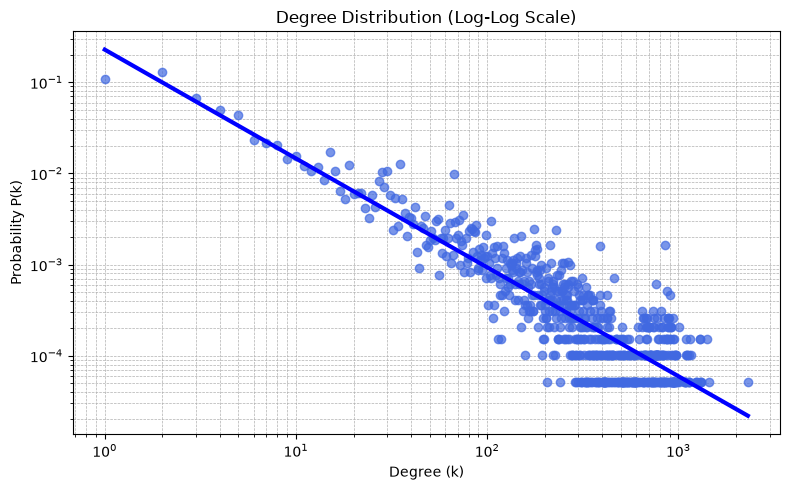

In [15]:
plt.figure(figsize=(8, 5))
plt.loglog(X, y, marker="o", linestyle="None", alpha=0.7, color="royalblue")
plt.loglog(X, np.exp(model.predict(log_X)), color="blue", linewidth=3)
plt.title("Degree Distribution (Log-Log Scale)")
plt.xlabel("Degree (k)")
plt.ylabel("Probability P(k)")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.tight_layout()
plt.show()

Ok THANK GOD, I got it. I'm gonna wrap all of this in a function.

In [23]:
def displayGraph(filename: str):
    with open(filename) as f:
        network = read_edgelist(f)
        k = measure_k(network)

    X,y,_ = k
    X = np.reshape(X, (-1, 1))
    y = np.reshape(y, (-1, 1))

    log_X = np.log(X)
    log_y = np.log(y)
    model = LinearRegression()
    model.fit(log_X, log_y)

    slope = model.coef_[0]     # This is -gamma
    intercept = model.intercept_
    print(f"slope: {slope}, intercept: {intercept}")

    plt.figure(figsize=(8, 5))
    plt.loglog(X, y, marker="o", linestyle="None", alpha=0.7, color="royalblue")
    plt.loglog(X, np.exp(model.predict(log_X)), color="blue", linewidth=3)
    plt.title(filename)
    plt.xlabel("Degree (k)")
    plt.ylabel("Probability P(k)")
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.tight_layout()
    plt.show()    
    

slope: [-1.19423985], intercept: [-1.47814474]


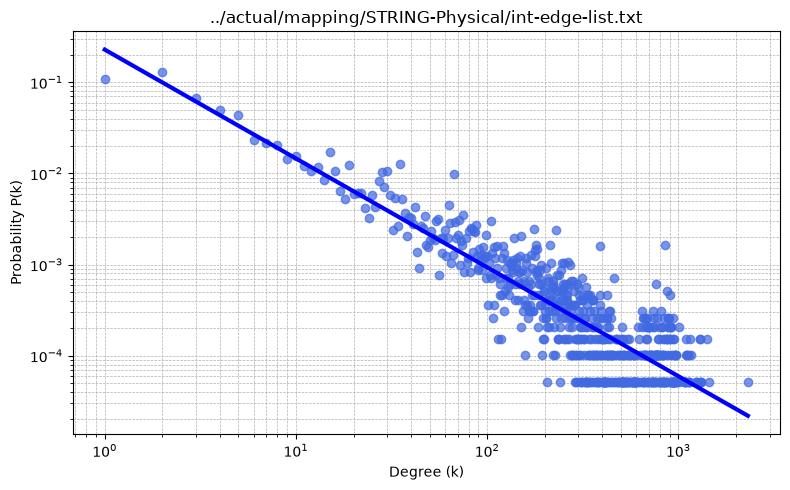

In [24]:
displayGraph("../actual/mapping/STRING-Physical/int-edge-list.txt")

slope: [-1.69766068], intercept: [0.90662032]


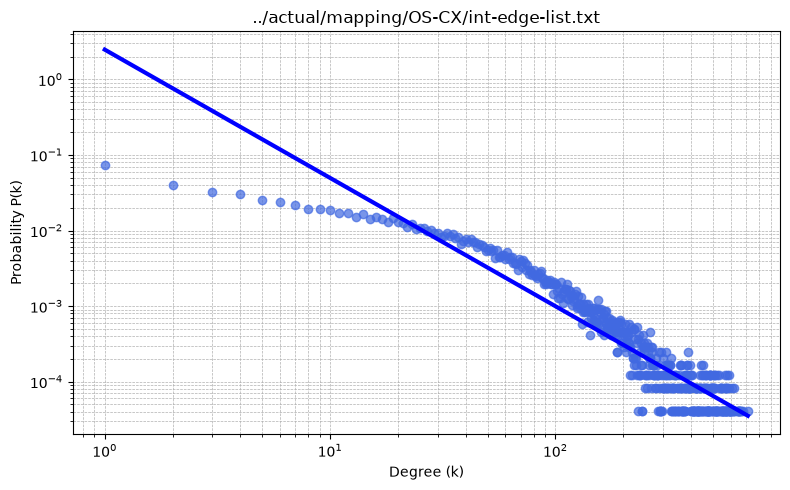

In [25]:
displayGraph("../actual/mapping/OS-CX/int-edge-list.txt")

slope: [-1.13966786], intercept: [-1.22880197]


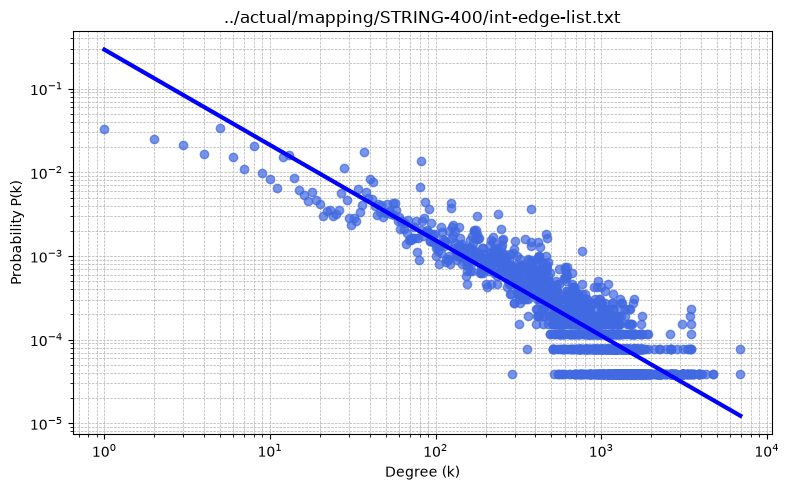

In [ ]:
displayGraph("../actual/mapping/STRING-400/int-edge-list.txt")

slope: [-0.54986949], intercept: [-4.92314836]


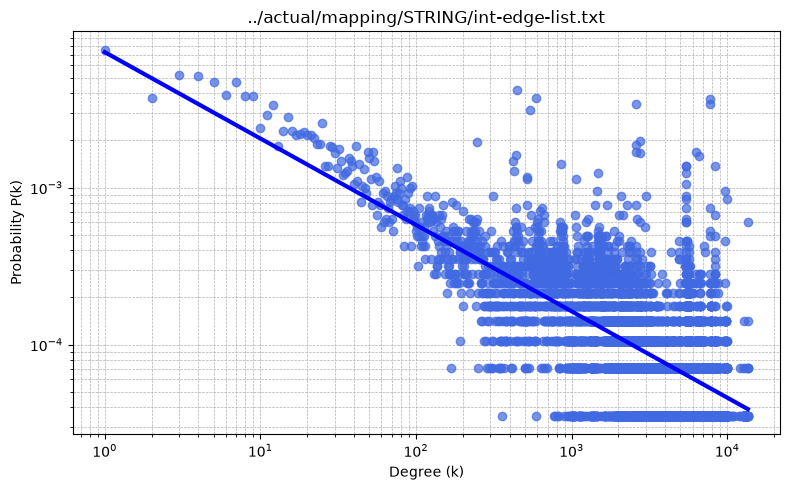

In [39]:
displayGraph("../actual/mapping/STRING/int-edge-list.txt")

slope: [-0.8875624], intercept: [-1.21100795]


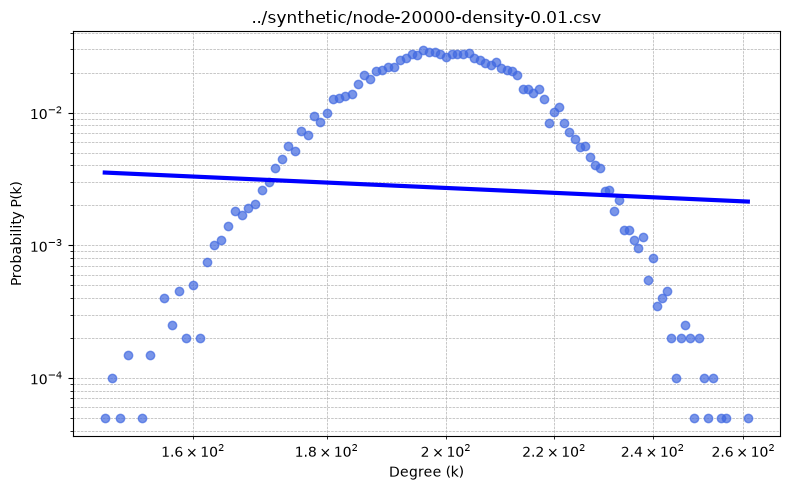

In [29]:
displayGraph("../synthetic/node-20000-density-0.01.csv")

slope: [-2.0481117], intercept: [2.51997309]


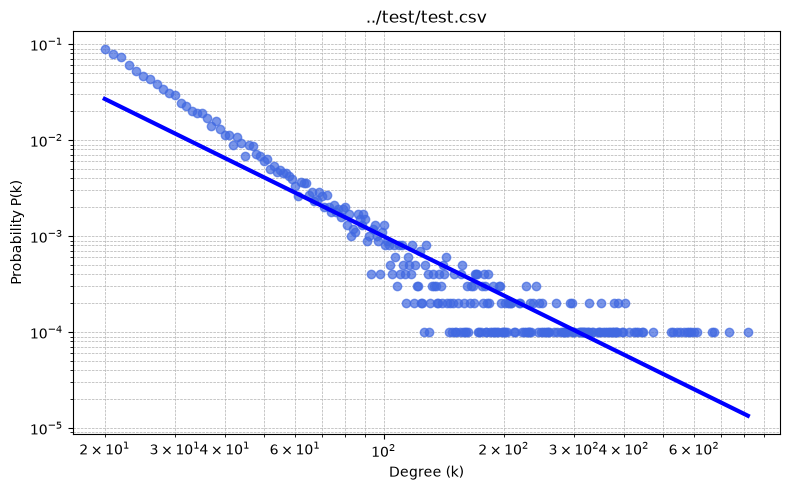

In [31]:
displayGraph("../test/test.csv")

In [37]:
node_count_list = [1024, 2048, 4096, 8192, 16384, 32768]
m_list = [8, 16, 32, 64, 128, 256, 512]
dir_path = "../synthetic/scale-free/"
from itertools import product


In [36]:
def load_graph_then_measure_k(n, m):
    filename = f"{dir_path}/n-{n}-m-{m}.csv"
    with open(filename) as f:
        network = read_edgelist(f)
        k = measure_k(network)

    X,y,_ = k
    X = np.reshape(X, (-1, 1))
    y = np.reshape(y, (-1, 1))

    log_X = np.log(X)
    log_y = np.log(y)
    model = LinearRegression()
    model.fit(log_X, log_y)

    slope = model.coef_[0]     # This is -gamma
    intercept = model.intercept_
    print(f"slope: {slope}, intercept: {intercept}, n: {n}, m: {m}")

In [38]:
report = []
for n, m in product(node_count_list, m_list):
    filename = f"{dir_path}/n-{n}-m-{m}.csv"
    with open(filename) as f:
        network = read_edgelist(f)
        k = measure_k(network)

    X,y,_ = k
    X = np.reshape(X, (-1, 1))
    y = np.reshape(y, (-1, 1))

    log_X = np.log(X)
    log_y = np.log(y)
    model = LinearRegression()
    model.fit(log_X, log_y)

    slope = model.coef_[0]     # This is -gamma
    intercept = model.intercept_
    report.append([n, m, slope, intercept])
    print(f"n: {n}, m: {m}, slope: {slope}, intercept: {intercept}")

n: 1024, m: 8, slope: [-1.88410534], intercept: [1.3803808]
n: 1024, m: 16, slope: [-1.91357174], intercept: [2.22968411]
n: 1024, m: 32, slope: [-1.78779947], intercept: [2.55336619]
n: 1024, m: 64, slope: [-1.71604435], intercept: [2.93610477]
n: 1024, m: 128, slope: [-1.71184074], intercept: [3.59446891]
n: 1024, m: 256, slope: [-1.42437025], intercept: [2.46674301]
n: 1024, m: 512, slope: [-1.04640001], intercept: [0.38379698]
n: 2048, m: 8, slope: [-1.94540473], intercept: [1.41363286]
n: 2048, m: 16, slope: [-1.95484233], intercept: [2.23665226]
n: 2048, m: 32, slope: [-1.90925978], intercept: [2.8494925]
n: 2048, m: 64, slope: [-1.85529264], intercept: [3.39243704]
n: 2048, m: 128, slope: [-1.74350659], intercept: [3.58150505]
n: 2048, m: 256, slope: [-1.6911153], intercept: [3.94527947]
n: 2048, m: 512, slope: [-1.42680086], intercept: [2.75220291]
n: 4096, m: 8, slope: [-1.98381619], intercept: [1.31857426]
n: 4096, m: 16, slope: [-2.00246562], intercept: [2.25055467]
n: 4096,